# 44 · Tabular Q-learning and the role of exploration

In [1]:
import numpy as np, gymnasium as gym, matplotlib.pyplot as plt

def value_iteration_policy(env, gamma=0.99):
    P, nS, nA = env.unwrapped.P, env.observation_space.n, env.action_space.n
    V = np.zeros(nS)
    for _ in range(2000):
        Q = np.array([[sum(p * (r + gamma * V[s2] * (not d)) for p, s2, r, d in P[s][a]) for a in range(nA)] for s in range(nS)])
        V = Q.max(1)
    return Q.argmax(1), V

def q_learning(env, episodes=5000, alpha=0.1, gamma=0.99, eps_start=1.0, eps_decay=0.999, eps_min=0.01, seed=0, optimistic=0.0, random_ties=True):
    rng = np.random.default_rng(seed)
    Q = np.full((env.observation_space.n, env.action_space.n), optimistic)
    returns, eps = [], eps_start
    for ep in range(episodes):
        s, _ = env.reset(seed=seed * 100000 + ep); done, G = False, 0.0
        while not done:
            greedy = int(rng.choice(np.flatnonzero(Q[s] == Q[s].max()))) if random_ties else int(Q[s].argmax())
            a = int(rng.integers(env.action_space.n)) if rng.random() < eps else greedy
            s2, r, te, tr, _ = env.step(a)
            target = r + gamma * Q[s2].max() * (not te)
            Q[s, a] += alpha * (target - Q[s, a])
            s, done, G = s2, te or tr, G + r
        returns.append(G); eps = max(eps_min, eps * eps_decay)
    return Q, np.array(returns)

def rolling(x, k=100):
    return np.convolve(x, np.ones(k) / k, mode="valid")

def evaluate(env, pi, n=500):
    w = 0
    for i in range(n):
        s, _ = env.reset(seed=10 ** 6 + i); done = False
        while not done:
            s, r, te, tr, _ = env.step(int(pi[s])); done = te or tr
        w += r
    return w / n

Q-learning greedy success: 1.0
agree with value iteration on visited states: 0.818 | note: several actions can be optimal (ties) in the deterministic grid


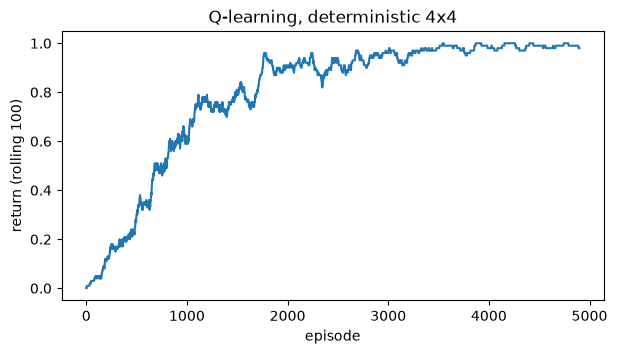

In [2]:
det = gym.make("FrozenLake-v1", is_slippery=False)
Q, R = q_learning(det)
pi_vi, _ = value_iteration_policy(det)
pi_q = Q.argmax(1)
desc = det.unwrapped.desc.astype(str).reshape(-1)
nonterminal = [s for s in range(16) if desc[s] not in "HG"]
reachable = [s for s in nonterminal if Q[s].any()]
print("Q-learning greedy success:", evaluate(det, pi_q))
print("agree with value iteration on visited states:", np.mean(pi_q[reachable] == pi_vi[reachable]).round(3),
      "| note: several actions can be optimal (ties) in the deterministic grid")
plt.figure(figsize=(7, 3.5)); plt.plot(rolling(R)); plt.xlabel("episode"); plt.ylabel("return (rolling 100)"); plt.title("Q-learning, deterministic 4x4"); plt.show()

ε decay 1 → 0.01           greedy success over 3 seeds: [0.52 0.75 0.74]


constant ε = 0.1           greedy success over 3 seeds: [0.75 0.75 0.75]


no exploration (ε = 0, argmax ties) greedy success over 3 seeds: [0. 0. 0.]


ε = 0 + optimistic init    greedy success over 3 seeds: [0.75 0.74 0.75]
value iteration optimum    0.74


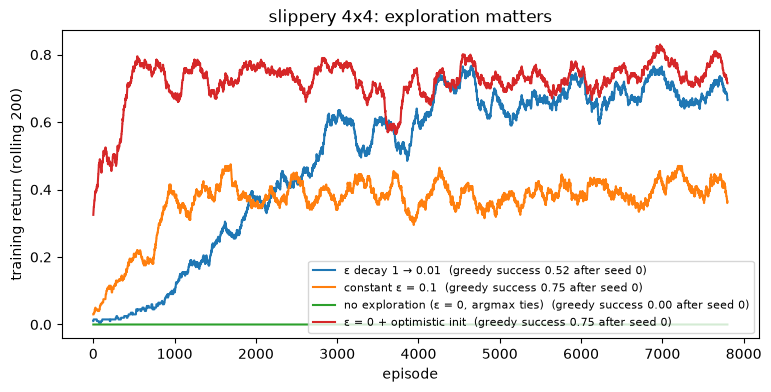

In [3]:
slip = gym.make("FrozenLake-v1", is_slippery=True)
pi_star, _ = value_iteration_policy(slip)
schedules = {"ε decay 1 → 0.01": dict(eps_start=1.0, eps_decay=0.999), "constant ε = 0.1": dict(eps_start=0.1, eps_decay=1.0, eps_min=0.1),
             "no exploration (ε = 0, argmax ties)": dict(eps_start=0.0, eps_decay=1.0, eps_min=0.0, random_ties=False), "ε = 0 + optimistic init": dict(eps_start=0.0, eps_decay=1.0, eps_min=0.0, optimistic=1.0, random_ties=False)}
plt.figure(figsize=(9, 4))
for name, kw in schedules.items():
    finals = []
    for seed in range(3):
        Q, R = q_learning(slip, episodes=8000, seed=seed, **kw)
        finals.append(evaluate(slip, Q.argmax(1)))
        if seed == 0:
            plt.plot(rolling(R, 200), label=f"{name}  (greedy success {np.mean(finals):.2f} after seed 0)")
    print(f"{name:26s} greedy success over 3 seeds: {np.round(finals, 2)}")
print(f"{'value iteration optimum':26s} {evaluate(slip, pi_star):.2f}")
plt.xlabel("episode"); plt.ylabel("training return (rolling 200)"); plt.legend(fontsize=8); plt.title("slippery 4x4: exploration matters"); plt.show()

In [4]:
big = gym.make("FrozenLake-v1", map_name="8x8", is_slippery=False)
for name, kw in [("ε decay", dict(eps_decay=0.9995)), ("ε = 0, random ties", dict(eps_start=0.0, eps_decay=1.0, eps_min=0.0)), ("ε = 0, argmax ties", dict(eps_start=0.0, eps_decay=1.0, eps_min=0.0, random_ties=False))]:
    Q, R = q_learning(big, episodes=10000, **kw)
    print(f"8x8 {name:8s}: first success at episode {int(np.argmax(R > 0)) if R.any() else 'never'}, greedy success {evaluate(big, Q.argmax(1), 100):.2f}")

8x8 ε decay : first success at episode 43, greedy success 1.00


8x8 ε = 0, random ties: first success at episode 1240, greedy success 1.00


8x8 ε = 0, argmax ties: first success at episode never, greedy success 0.00
